# 📘 Predicting Will It Rain Tomorrow Using End-to-End Data Science Pipeline

In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, get_scorer_names
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [2]:
# Load the Dataset
df = pd.read_csv('assignment2_australia_weather.csv')
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


In [3]:
# Remove irrelevant columns
df = df.drop(columns=['Date', 'Location', 'RISK_MM'])
# How many fields are missing.
print(f'Total number of records: {df.shape[0]}')
num_features = df.select_dtypes(include='number')
cat_features = df.select_dtypes(exclude='number')
print(f'Number of missing values in numeric features:\n{num_features.isnull().sum()}\n')
print(f'Number of missing values in categorical features:\n{cat_features.isnull().sum()}')

Total number of records: 142193
Number of missing values in numeric features:
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustSpeed     9270
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
dtype: int64

Number of missing values in categorical features:
WindGustDir      9330
WindDir9am      10013
WindDir3pm       3778
RainToday        1406
RainTomorrow        0
dtype: int64


In [4]:
df[cat_features.columns].nunique()

WindGustDir     16
WindDir9am      16
WindDir3pm      16
RainToday        2
RainTomorrow     2
dtype: int64

## 📊 Visualize the Dataset

In [5]:
dropped_df = df.dropna().copy()
# Encode categorical variables numerically (label encoding)
for col in dropped_df.select_dtypes(include="string").columns:
    dropped_df[col] = dropped_df[col].astype("category").cat.codes

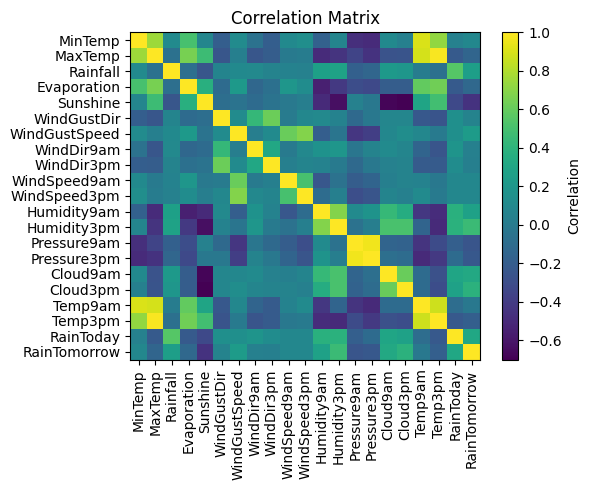

In [6]:
# Generate a correlation matrix
corr = dropped_df.corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [7]:
# Rank correlations
corr['RainTomorrow'].sort_values(ascending=False)

RainTomorrow     1.000000
Humidity3pm      0.455358
Cloud3pm         0.388574
Cloud9am         0.323972
RainToday        0.309098
Humidity9am      0.271033
Rainfall         0.254342
WindGustSpeed    0.233158
WindSpeed3pm     0.088862
MinTemp          0.087428
WindSpeed9am     0.083904
WindGustDir      0.061751
WindDir9am       0.035992
WindDir3pm       0.032203
Temp9am         -0.018179
Evaporation     -0.130002
MaxTemp         -0.147467
Temp3pm         -0.183586
Pressure3pm     -0.230418
Pressure9am     -0.254816
Sunshine        -0.453407
Name: RainTomorrow, dtype: float64

## 🧹 Data Preparation

In [8]:
# Remove exact duplicate rows
df = df.drop_duplicates()
# Fill remaining missing values with median for numeric columns and mode for categorical columns.
num_pipe = Pipeline([
    ('numericalImputer', SimpleImputer(strategy='median')),
    ('numericalScaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('categoricalImputer', SimpleImputer(strategy="most_frequent")),
    ('categoricalEncoder', OneHotEncoder(handle_unknown='ignore'))
])
# Make column transformer
col_transformer = ColumnTransformer(transformers=[
    ('numerical', num_pipe, num_features.columns),
    ('categorical', cat_pipe, cat_features.columns.drop('RainTomorrow'))], remainder='drop')

X = df.drop(columns=['RainTomorrow'])
y = df['RainTomorrow']

## ✂️ Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 🤖 Train the Model

In [10]:
def trainer(model, X_train, y_train, X_test, y_test, algo):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    print(algo)
    # Evaluation
    print("    Accuracy:", accuracy_score(y_test, y_pred))
    print("    AUC score:", roc_auc_score(y_test, y_pred_prob))
    # Cross validation
    scores = cross_validate(model, X_train, y_train, cv=5, scoring=('accuracy', 'roc_auc'))
    print('  Cross-validation:')
    print('    Accuracy:', scores['test_accuracy'].mean())
    print('    AUC score:', scores['test_roc_auc'].mean())
    print('\n')

## 🔮 Run Pipelines

When I performed LogisticRegression and RandomForestClassifier on this dataset for assignment 2, the following performance metrics were observed:

* LogisticRegression
    * Accuracy: 0.8421737601125572
    * AUC score:  0.8625032736034286
* RandomForestClassifier
    * Accuracy: 0.8546957439324657
    * AUC score:  0.8814035779523699

In [11]:
#print(get_scorer_names())
lg_model = Pipeline([
    ('columnTransformer', col_transformer),
    ('estimator', LogisticRegression(max_iter=10000))
])
trainer(lg_model, X_train, y_train, X_test, y_test, 'Logistic Regression')
rf_model = Pipeline([
    ('columnTransformer', col_transformer),
    ('estimator', RandomForestClassifier(n_estimators=100, random_state=42))
])
trainer(rf_model, X_train, y_train, X_test, y_test, 'Random Forest Classifier')

Logistic Regression
    Accuracy: 0.8432993316918748
    AUC score: 0.8648829161359083
  Cross-validation:
    Accuracy: 0.8430313751902325
    AUC score: 0.8654168709379089


Random Forest Classifier
    Accuracy: 0.8529018642279282
    AUC score: 0.8795521610769621
  Cross-validation:
    Accuracy: 0.8536454530411841
    AUC score: 0.8795217988122086




The scores for Logistic Regression and Random Forest Classifier were similar to the scores calculated in assignment 2, with Random Forest Classifier having the best performance.

## 🔮 Tune Hyperparameters for Random Forest

In [12]:
params = {
    'estimator__n_estimators': [25,50,100,200],
    'estimator__max_depth': [3,5,7,10],
    'estimator__min_samples_split': [1,2,5],
    'estimator__min_samples_leaf': [1,2,5]
}

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=params,
    n_iter=20, 
    cv=5,     
    scoring=('accuracy', 'roc_auc'),
    refit='accuracy',
    verbose=0,
    n_jobs=-1 
)

random_search.fit(X_train, y_train) 
print(f"Best score: {random_search.best_score_}")
print(f"Best parameters: {random_search.best_params_}")

C:\Users\hsfer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
20 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\hsfer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hsfer\AppData\Local\Packages\PythonSoftwareFoundat

Best score: 0.8450187681872299
Best parameters: {'estimator__n_estimators': 200, 'estimator__min_samples_split': 2, 'estimator__min_samples_leaf': 2, 'estimator__max_depth': 10}


Due to my relative ignorance if RandomSearchCV, I don't understand why some of the fits failed. The best score was inferior to the accuracy score of the original run of the Random Forest Classifier, though it is possible that different parameters (or using GridSearchCV to search all combinations) could produce an improved model.

Generally speaking, the more complex the model, the slower its performance. For example, increasing the number of iterations (n_iter) in Random Forest increases the run time of a model. 

Pipelines are beneficial because they allow the combination of multiple preproceesing steps into a single object, simplifying readabilty and easing experimentation since changing a preprocessing step only requires a single change to the pipeline instead of multiple data transformation needed when not using them.